In [1]:
import pandas as pd
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
iris = load_iris()
X = iris.data
y = iris.target
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.3,
    random_state=42
)

In [4]:
svm_model = SVC(kernel='linear')
svm_model.fit(X_train, y_train)
y_pred_svm = svm_model.predict(X_test)
accuracy_score(y_test, y_pred_svm)

0.9777777777777777

In [5]:
confusion_matrix(y_test, y_pred_svm)

array([[19,  0,  0],
       [ 0, 12,  1],
       [ 0,  0, 13]])

In [6]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
accuracy_score(y_test, y_pred_rf)
confusion_matrix(y_test, y_pred_rf)

array([[19,  0,  0],
       [ 0, 13,  0],
       [ 0,  0, 13]])

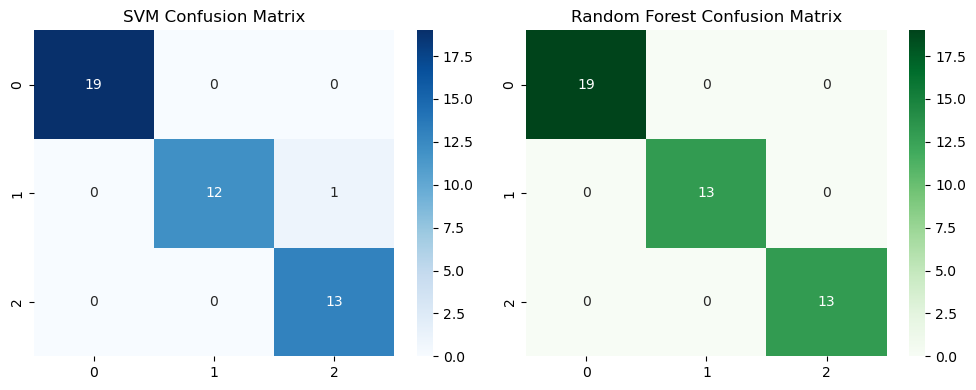

In [10]:
plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
sns.heatmap(
    confusion_matrix(y_test, y_pred_svm),
    annot=True,
    cmap='Blues',
    fmt='d')
plt.title("SVM Confusion Matrix")

plt.subplot(1,2,2)
sns.heatmap(
    confusion_matrix(y_test, y_pred_rf), 
    annot=True, 
    cmap='Greens', 
    fmt='d')
plt.title("Random Forest Confusion Matrix")
plt.tight_layout()
plt.show()